In [8]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.8.0


In [9]:
diabetes = load_diabetes(as_frame = True)

x =  diabetes.data
y = diabetes.target

print("Features shape:", x.shape)
print("Target Shape:", y.shape)

display(x.head())
display(y.head())

print("Feature names:", x.columns.tolist())

Features shape: (442, 10)
Target Shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64

Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size = 0.2,
    random_state=42
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test)),

Training samples: 353
Testing samples: 89


(None,)

In [11]:
model = LinearRegression()
model.fit(x_train, y_train)
print("Training complete!")

Training complete!


In [13]:
y_pred = model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 3))


MAE: 42.79
MSE: 2900.19
RMSE: 53.85
R²: 0.453


,Actual,Predicted
0,219.0,139.547558
1,70.0,179.517208
2,202.0,134.038756
3,230.0,291.417029
4,111.0,123.789659
5,84.0,92.172347
6,242.0,258.232389
7,272.0,181.337321
8,94.0,90.224113
9,96.0,108.633759


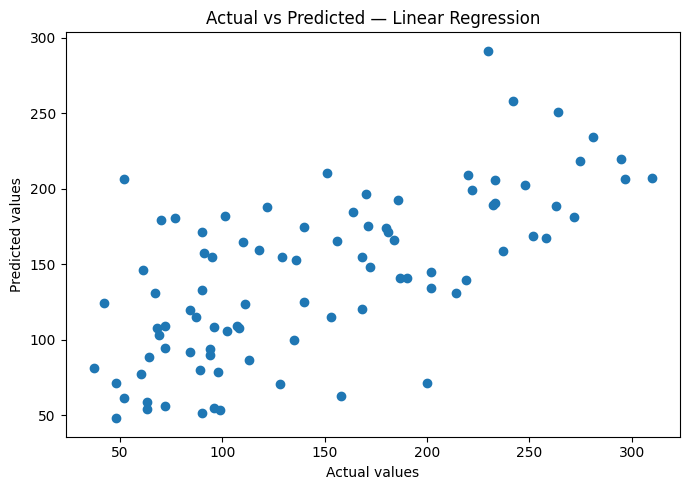

In [14]:
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

display(comparison.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted — Linear Regression")
plt.tight_layout()
plt.show()